# 03_07 — Pré-treinamento PatchTST na Austrália (240 → 24 h)

**Objetivo:** comparar dois pré-treinamentos australianos da **mesma arquitetura PatchTST compacta**: (1) somente potência e (2) potência + meteorologia, com encoder compartilhado entre canais. A entrada do previsor final é **sempre somente potência**. A segunda variante recebe supervisão auto-supervisionada adicional por reconstrução de patches históricos mascarados de todas as variáveis disponíveis, sem usar meteorologia futura.

**Fonte:** Nie et al. (2023), *A Time Series is Worth 64 Words* (PatchTST), e Bak et al. (2025), *Transfer Learning for Photovoltaic Power Forecasting Across Regions Using Large-Scale Datasets*, IEEE Access, DOI: 10.1109/ACCESS.2025.3591040.

**Importante:** esta é uma **adaptação experimental**, não reprodução fiel dos pesos, arquitetura grande, objetivos de treino, conjunto de dados multiusina ou resultados de Bak et al. (2025). Base de entrada: arquivos NPZ do seu `03_04`, com 240 horas históricas, 24 valores futuros e 5 variáveis australianas. Não acessa dados brasileiros nem o teste australiano para selecionar pesos.

**Controle metodológico:** sem escalas nominais presumidas. A potência retorna a kW usando o fator armazenado no NPZ, e um novo Min–Max é ajustado somente com treino australiano. As quatro variáveis meteorológicas preservam o z-score realizado no `03_04` com treino.

## 1. Ambiente, parâmetros e saídas

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, random, json, copy, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as arquivo:
        for parte in iter(lambda: arquivo.read(1024*1024), b''):
            h.update(parte)
    return h.hexdigest()

def seed_tudo(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
else:
    print('AVISO: GPU CUDA indisponível. Treino em CPU.')
RAIZ = next((f for f in [Path.cwd(), *Path.cwd().parents]
             if (f/'data/processed/sequencias_temporais_24h').is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError('Pasta data/processed/sequencias_temporais_24h não encontrada; execute 03_04 no projeto.')
TENSORES = RAIZ/'data/processed/sequencias_temporais_24h'

HISTORICO,HORIZONTE=240,24
SEEDS=[42]     # Expanda posteriormente para [42,123,2026] repetindo também o fine-tuning
BATCH_SIZE=16  # Se ocorrer CUDA OOM na RTX 3050, reduzir para 8
EPOCAS=65
PACIENCIA=12
LR=1e-3
WEIGHT_DECAY=1e-4
LAMBDA_SSL=0.25          # Peso da reconstrução Huber em patches mascarados
MASCARA_FRAC=0.25
DELTA_HUBER=0.05
AVALIAR_TESTE_AUSTRALIANO=False # Somente depois de fixar os hiperparâmetros
SAIDA_BASE=RAIZ/'reports/tcc/03_07_pretreino_patchtst'
SAIDA_BASE.mkdir(parents=True,exist_ok=True)
print('Pasta de dados:',TENSORES)
print('Pasta de checkpoints:',SAIDA_BASE)


GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Pasta de dados: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\data\processed\sequencias_temporais_24h
Pasta de checkpoints: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_07_pretreino_patchtst


## 2. Ler NPZ australianos, auditar timestamps e ajustar Min–Max apenas no treino

In [2]:
def ler_npz(dominio, part):
    if dominio not in {'australia','brasil'} or part not in {'treino','validacao','teste'}:
        raise ValueError('Domínio/partição inválidos')
    arq = TENSORES/f'{dominio}_{part}_L{HISTORICO}_H{HORIZONTE}.npz'
    if not arq.is_file(): raise FileNotFoundError(f'Não encontrado: {arq}')
    with np.load(arq,allow_pickle=False) as z:
        d={k:z[k].copy() for k in z.files}
    required={'X','X_potencia','y','y_kw','features','capacidade_kw','timestamps_X','timestamps_y','emissao','mask_y_observado'}
    if missing:=required-set(d): raise ValueError(f'{arq.name}: campos faltantes {missing}')
    n=len(d['y']); c=5 if dominio=='australia' else 1
    assert d['X'].shape==(n,HISTORICO,c), (arq,d['X'].shape)
    assert d['X_potencia'].shape==(n,HISTORICO,1)
    assert d['y'].shape==(n,HORIZONTE) and d['y_kw'].shape==(n,HORIZONTE)
    esperado=(['Global_Horizontal_Radiation','Weather_Temperature_Celsius',
              'Weather_Relative_Humidity','Wind_Speed','Active_Power'] if c==5 else ['Active_Power'])
    if list(d['features'])!=esperado: raise ValueError(f'Ordenação de canais inesperada em {arq.name}')
    if not np.isfinite(d['X']).all() or not np.isfinite(d['y_kw']).all():
        raise ValueError('Dados não finitos no NPZ')
    if not d['mask_y_observado'].all(): raise ValueError('Alvos interpolados/não observados no NPZ')
    fator=float(d['capacidade_kw'])
    if not np.isfinite(fator) or fator<=0: raise ValueError('Fator antigo do 03_04 inválido')
    if not np.allclose(d['X'][:,:,-1],d['X_potencia'][:,:,0],atol=1e-6):
        raise ValueError('Potência nos canais incompatível')
    if not np.allclose(d['y']*fator,d['y_kw'],atol=1e-3,rtol=4e-5):
        raise ValueError('Alvos em kW inconsistentes com antigo fator do 03_04')
    if n:
        if not np.all(np.diff(d['timestamps_X'],axis=1)==np.timedelta64(1,'h')):
            raise ValueError('Histórico cruza lacuna temporal')
        if not np.all(np.diff(d['timestamps_y'],axis=1)==np.timedelta64(1,'h')):
            raise ValueError('Horizonte cruza lacuna temporal')
        if not np.all(d['timestamps_X'][:,-1]+np.timedelta64(1,'h')==d['emissao']):
            raise ValueError('Emissão incompatível com histórico')
        if not np.all(d['timestamps_y'][:,0]==d['emissao']):
            raise ValueError('Emissão incompatível com alvo')
    d.update(fator_antigo=fator,arquivo=str(arq),hash_sha256=sha256(arq))
    return d

def parametros_de_treino(raw):
    """Usa exclusivamente o período de treino; amostras sobrepostas não alteram extremos."""
    fator=raw['fator_antigo']
    baixo=min(float(raw['X_potencia'].min())*fator, float(raw['y_kw'].min()))
    alto=max(float(raw['X_potencia'].max())*fator, float(raw['y_kw'].max()))
    if not np.isfinite(alto-baixo) or alto<=baixo:
        raise ValueError('MinMax inválido')
    return {'min_kw':baixo,'max_kw':alto,'amplitude_kw':alto-baixo,
            'fator_original_03_04_kw':fator,'metodo':'minmax_treino_historicos_e_alvos',
            'clipping':False}

def normalizar(raw,escala):
    if not np.isclose(raw['fator_antigo'],escala['fator_original_03_04_kw']):
        raise ValueError('Fator antigo inconsistente entre partições')
    x=raw['X'].astype(np.float32).copy()
    potencia_kw=raw['X_potencia'][:,:,0].astype(np.float64)*raw['fator_antigo']
    x[:,:,-1]=((potencia_kw-escala['min_kw'])/escala['amplitude_kw']).astype(np.float32)
    y=((raw['y_kw'].astype(np.float64)-escala['min_kw'])/escala['amplitude_kw']).astype(np.float32)
    if not np.isfinite(x).all() or not np.isfinite(y).all(): raise ValueError('Normalização inválida')
    return {'x':np.ascontiguousarray(x),'y':np.ascontiguousarray(y),
            'y_kw':raw['y_kw'].astype(np.float64),
            'timestamps_y':raw['timestamps_y'],'emissao':raw['emissao']}

def loader(dados, batch_size, embaralhar=False):
    ds=TensorDataset(torch.from_numpy(dados['x']),torch.from_numpy(dados['y']))
    return DataLoader(ds,batch_size=batch_size,shuffle=embaralhar,num_workers=0,
                      pin_memory=DEVICE.type=='cuda')

def desnormalizar(y,escala):
    return np.asarray(y,dtype=np.float64)*escala['amplitude_kw']+escala['min_kw']

def resumo_metricas(dados,pred,escala):
    real=dados['y_kw']; estimado=np.maximum(0,desnormalizar(pred,escala))
    if estimado.shape!=real.shape:raise ValueError('Previsão e alvo incompatíveis')
    erros=estimado-real
    den=((real-real.mean())**2).sum()
    horas=pd.to_datetime(dados['timestamps_y'].reshape(-1)).hour.to_numpy().reshape(real.shape)
    dia=(horas>=6)&(horas<18)
    return {'n_janelas':len(real),'mae_kw':float(np.abs(erros).mean()),
            'rmse_kw':float(np.sqrt(np.square(erros).mean())),
            'r2':float(1-np.square(erros).sum()/den) if den>1e-8 else np.nan,
            'bias_kw':float(erros.mean()),
            'mae_diurno_kw':float(np.abs(erros[dia]).mean()) if dia.any() else np.nan,
            'wape_diurno_pct':float(100*np.abs(erros[dia]).sum()/np.abs(real[dia]).sum()) if dia.any() and np.abs(real[dia]).sum()>0 else np.nan}

@torch.no_grad()
def prever(modelo,dados,batch_size=32):
    modelo.eval()
    resp=[]
    for (x,) in DataLoader(TensorDataset(torch.from_numpy(dados['x'])),batch_size=batch_size):
        resp.append(modelo(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(resp) if resp else np.empty((0,HORIZONTE),np.float32)

raw_train=ler_npz('australia','treino')
raw_val=ler_npz('australia','validacao')
assert len(raw_train['y']) and len(raw_val['y'])
if not raw_train['timestamps_y'].max() < raw_val['timestamps_y'].min():
    raise ValueError('Treino e validação não estão separados cronologicamente')
ESCALA_AU=parametros_de_treino(raw_train)
TREINO=normalizar(raw_train,ESCALA_AU)
VALIDACAO=normalizar(raw_val,ESCALA_AU)
print('Escala australiana (somente treino):',ESCALA_AU)
print('Treino:',TREINO['x'].shape,TREINO['y'].shape)
print('Validação:',VALIDACAO['x'].shape,VALIDACAO['y'].shape)
print('Ordem dos canais:',list(raw_train['features']))


Escala australiana (somente treino): {'min_kw': 0.0, 'max_kw': 21.62686586380005, 'amplitude_kw': 21.62686586380005, 'fator_original_03_04_kw': 24.0, 'metodo': 'minmax_treino_historicos_e_alvos', 'clipping': False}
Treino: (5160, 240, 5) (5160, 24)
Validação: (1503, 240, 5) (1503, 24)
Ordem dos canais: [np.str_('Global_Horizontal_Radiation'), np.str_('Weather_Temperature_Celsius'), np.str_('Weather_Relative_Humidity'), np.str_('Wind_Speed'), np.str_('Active_Power')]


## 3. Arquitetura compacta Channel-Independent PatchTST

O **encoder Transformer é compartilhado entre canais**. Na previsão de potência, só o canal `Active_Power` alimenta a cabeça supervisionada. O objetivo auto-supervisionado mascara trechos **do próprio histórico** e treina o encoder para reconstruí-los. Isso não utiliza valores meteorológicos do horizonte futuro. A reconstrução apenas alimenta a otimização do encoder; não faz parte da inferência brasileira.

In [3]:
class PatchTSTCompartilhado(nn.Module):
    """PatchTST compacto e channel-independent (adaptação experimental, não cópia do repositório IEEE).

    Um mesmo encoder recebe qualquer quantidade de canais de entrada, sempre tratando
    cada canal como uma série univariada. A previsão supervisionada usa somente o
    último canal, que é Active_Power no NPZ australiano e o único no brasileiro.
    O decodificador SSL reconstrói patches históricos mascarados (sem usar dados futuros).
    """
    def __init__(self, hist=240, horizon=24, patch_len=24, stride=8,
                 dim=64, heads=4, layers=2, ff_dim=128, dropout=0.10):
        super().__init__()
        if hist < patch_len or (hist-patch_len) % stride:
            raise ValueError('É necessário (hist - patch_len) divisível por stride, neste experimento.')
        if dim % heads:
            raise ValueError('dim deve ser múltiplo de heads')
        self.hist, self.horizon = int(hist), int(horizon)
        self.patch_len, self.stride = int(patch_len), int(stride)
        self.n_patches = 1+(hist-patch_len)//stride
        self.dim = int(dim)
        self.embed = nn.Linear(patch_len, dim)
        self.pos = nn.Parameter(torch.zeros(1, self.n_patches, dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.mask_token = nn.Parameter(torch.zeros(dim))
        nn.init.normal_(self.mask_token, std=0.02)
        camada = nn.TransformerEncoderLayer(d_model=dim, nhead=heads,
                  dim_feedforward=ff_dim, dropout=dropout,
                  batch_first=True, activation='gelu', norm_first=False)
        self.encoder = nn.TransformerEncoder(camada, num_layers=layers,
                                             enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Flatten(start_dim=1),
                                  nn.Linear(dim*self.n_patches, horizon))
        self.recon = nn.Linear(dim, patch_len)

    def patches(self, x):
        if x.ndim != 3 or x.shape[1] != self.hist:
            raise ValueError(f'Esperado (batch,{self.hist},canais), recebido {tuple(x.shape)}')
        return x.transpose(1,2).unfold(-1, self.patch_len, self.stride).contiguous()

    def representar(self, x, mascara=None):
        patches = self.patches(x)  # [B,C,P,patch_len]
        b,c,p,l = patches.shape
        emb = self.embed(patches).reshape(b*c, p, self.dim)
        if mascara is not None:
            if mascara.shape != (b,c,p):
                raise ValueError('Formato da máscara incompatível')
            m = mascara.reshape(b*c,p,1)
            emb = torch.where(m, self.mask_token.view(1,1,-1), emb)
        emb = emb + self.pos
        enc = self.encoder(emb)
        return enc.reshape(b,c,p,self.dim), patches

    def forward(self, x):
        # IMPORTANTE: potência é sempre o último canal em ambos os domínios.
        z,_ = self.representar(x[:,:,-1:])
        return self.head(z[:,0])

    def masked_loss(self, x, taxa=0.25, delta=0.05):
        b,c = x.shape[0], x.shape[-1]
        mascara = torch.rand(b,c,self.n_patches,device=x.device) < taxa
        # Garante pelo menos um patch mascarado por série.
        indice = torch.randint(self.n_patches,(b,c), device=x.device)
        mascara.scatter_(2, indice.unsqueeze(-1), True)
        z, patches = self.representar(x, mascara)
        saida = self.recon(z)
        erro = nn.functional.huber_loss(saida,patches,delta=delta,reduction='none')
        # Média somente em posições mascaradas, tanto no cenário uni quanto multi.
        m = mascara.unsqueeze(-1).expand_as(erro)
        return erro[m].mean()

CONFIG_MODELO = dict(hist=HISTORICO, horizon=HORIZONTE, patch_len=24,
                     stride=8, dim=64, heads=4, layers=2, ff_dim=128, dropout=0.10)
assert CONFIG_MODELO['hist']==240 and CONFIG_MODELO['horizon']==24
_tmp=PatchTSTCompartilhado(**CONFIG_MODELO)
print('Patches por canal:',_tmp.n_patches, '| parâmetros:',sum(p.numel() for p in _tmp.parameters()))
del _tmp


Patches por canal: 28 | parâmetros: 114992


## 4. Treinar duas variantes com arquitetura idêntica

- **Univariado**: uma variável (potência) tanto para previsão como para reconstrução dos patches mascarados.
- **Multivariado**: cinco canais usados no objetivo de reconstrução, mantendo **previsão apenas com potência**.

O melhor checkpoint de cada variante é selecionado **somente pelo MAE de previsão da potência na validação australiana**, nunca pelo erro de reconstrução.

In [4]:
def epoca_treino(modelo,carregador,otimizador):
    modelo.train(); soma_p=soma_ssl=n=0
    for x,y in carregador:
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        otimizador.zero_grad(set_to_none=True)
        yp=modelo(x)            # y prevista SOMENTE da potência (último canal)
        loss_p=nn.functional.huber_loss(yp,y,delta=DELTA_HUBER)
        loss_ssl=modelo.masked_loss(x, taxa=MASCARA_FRAC, delta=DELTA_HUBER)
        loss=loss_p+LAMBDA_SSL*loss_ssl
        loss.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(),1.0)
        otimizador.step()
        soma_p+=loss_p.item()*len(x)
        soma_ssl+=loss_ssl.item()*len(x)
        n+=len(x)
    return soma_p/max(n,1), soma_ssl/max(n,1)

@torch.no_grad()
def mae_val_normalizada(modelo,carregador):
    modelo.eval();total=0.0;n=0
    for x,y in carregador:
        x=x.to(DEVICE);y=y.to(DEVICE)
        # O próprio forward sempre usa potência exclusivamente.
        yp=modelo(x)
        total+=(yp-y).abs().sum().item();n+=y.numel()
    return total/max(n,1)

historicos=[]; resultados=[]
for seed in SEEDS:
    dir_seed=SAIDA_BASE/f'L{HISTORICO}_H{HORIZONTE}_seed{seed}'
    dir_seed.mkdir(parents=True,exist_ok=True)
    (dir_seed/'normalizacao_australia.json').write_text(json.dumps(ESCALA_AU,indent=2),encoding='utf-8')
    for variante in ['univariado','multivariado']:
        seed_tudo(seed)
        xtr=TREINO['x'][:,:,-1:] if variante=='univariado' else TREINO['x']
        xval=VALIDACAO['x'][:,:,-1:] if variante=='univariado' else VALIDACAO['x']
        ds_tr={'x':np.ascontiguousarray(xtr),'y':TREINO['y']}
        ds_val={'x':np.ascontiguousarray(xval),'y':VALIDACAO['y']}
        treino_loader=loader(ds_tr,BATCH_SIZE,True)
        val_loader=loader(ds_val,BATCH_SIZE,False)
        modelo=PatchTSTCompartilhado(**CONFIG_MODELO).to(DEVICE)
        otimizador=torch.optim.AdamW(modelo.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
        scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador,mode='min',factor=0.5,patience=4)
        melhor=np.inf;paradas=0;melhor_ep=None
        caminho=dir_seed/f'patchtst_australia_{variante}.pt'
        inicio=time.perf_counter()
        for ep in range(1,EPOCAS+1):
            lp,lssl=epoca_treino(modelo,treino_loader,otimizador)
            val_mae=mae_val_normalizada(modelo,val_loader)
            scheduler.step(val_mae)
            historicos.append({'seed':seed,'variante':variante,'epoca':ep,
                               'loss_previsao_treino':lp,'loss_reconstrucao_treino':lssl,
                               'mae_validacao_normalizado':val_mae,'lr':otimizador.param_groups[0]['lr']})
            if val_mae<melhor-1e-7:
                melhor=val_mae;melhor_ep=ep;paradas=0
                torch.save({'architecture':'PatchTSTCompartilhado','variant':variante,
                            'model_state_dict':copy.deepcopy(modelo.state_dict()),
                            'model_config':dict(CONFIG_MODELO),'seed':seed,
                            'best_epoch':ep,'val_mae_normalizado':melhor,
                            'normalizacao_origem':ESCALA_AU,
                            'features_pretrain':[str(v) for v in raw_train['features']] if variante=='multivariado' else ['Active_Power'],
                            'hash_npz_treino':raw_train['hash_sha256'],
                            'hash_npz_validacao':raw_val['hash_sha256'],
                            'ssl_lambda':LAMBDA_SSL,'ssl_mask_ratio':MASCARA_FRAC},caminho)
            else:paradas+=1
            if ep==1 or ep%5==0 or paradas>=PACIENCIA:
                print(f'{variante} seed={seed} ep {ep:03d} | previsao={lp:.5f} '
                      f'| masked={lssl:.5f} | MAE val={val_mae:.5f} | LR={otimizador.param_groups[0]["lr"]:.1e}')
            if paradas>=PACIENCIA:break
        ck=torch.load(caminho,map_location='cpu',weights_only=True)
        modelo.load_state_dict(ck['model_state_dict'],strict=True)
        modelo.to(DEVICE)
        # Teste de independência: o modelo multivariado carrega e prevê SÓ potência.
        pred_uni=prever(modelo,{'x':VALIDACAO['x'][:,:,-1:].copy()},BATCH_SIZE)
        pred_full=prever(modelo,ds_val,BATCH_SIZE)
        if not np.allclose(pred_uni,pred_full,atol=1e-5,rtol=1e-5):
            raise AssertionError('Previsão depende de variáveis meteorológicas na inferência')
        met=resumo_metricas(VALIDACAO,pred_uni,ESCALA_AU)
        met.update(variante=variante,seed=seed,melhor_epoca=melhor_ep,
                   tempo_s=time.perf_counter()-inicio,checkpoint=str(caminho))
        resultados.append(met)
        print('Checkpoint:',caminho,'| MAE validação kW:',round(met['mae_kw'],4))
        del modelo
        if DEVICE.type=='cuda':torch.cuda.empty_cache()

pd.DataFrame(historicos).to_csv(SAIDA_BASE/'historico_treinamento.csv',index=False)
tabela_au=pd.DataFrame(resultados).sort_values(['seed','variante'])
tabela_au.to_csv(SAIDA_BASE/'metricas_validacao_australia.csv',index=False)
display(tabela_au.round(4))


univariado seed=42 ep 001 | previsao=0.00488 | masked=0.01364 | MAE val=0.08447 | LR=1.0e-03
univariado seed=42 ep 005 | previsao=0.00209 | masked=0.01222 | MAE val=0.06749 | LR=1.0e-03
univariado seed=42 ep 010 | previsao=0.00184 | masked=0.00384 | MAE val=0.06419 | LR=1.0e-03
univariado seed=42 ep 015 | previsao=0.00170 | masked=0.00236 | MAE val=0.07289 | LR=1.0e-03
univariado seed=42 ep 020 | previsao=0.00163 | masked=0.00216 | MAE val=0.06231 | LR=1.0e-03
univariado seed=42 ep 025 | previsao=0.00154 | masked=0.00206 | MAE val=0.06256 | LR=1.0e-03
univariado seed=42 ep 030 | previsao=0.00140 | masked=0.00197 | MAE val=0.06229 | LR=5.0e-04
univariado seed=42 ep 035 | previsao=0.00131 | masked=0.00193 | MAE val=0.06189 | LR=2.5e-04
univariado seed=42 ep 040 | previsao=0.00126 | masked=0.00192 | MAE val=0.06172 | LR=1.3e-04
univariado seed=42 ep 045 | previsao=0.00123 | masked=0.00190 | MAE val=0.06209 | LR=6.3e-05
univariado seed=42 ep 046 | previsao=0.00122 | masked=0.00190 | MAE va

,n_janelas,mae_kw,rmse_kw,r2,bias_kw,mae_diurno_kw,wape_diurno_pct,variante,seed,melhor_epoca,tempo_s,checkpoint
1,1503,1.2173,2.5695,0.8909,0.4174,2.2510,17.2925,multivariado,42,62,477.1877,c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\r...
0,1503,1.2654,2.6257,0.8861,0.4415,2.3356,17.9424,univariado,42,34,410.8236,c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\r...


## 5. Gráficos e manifesto de reprodutibilidade

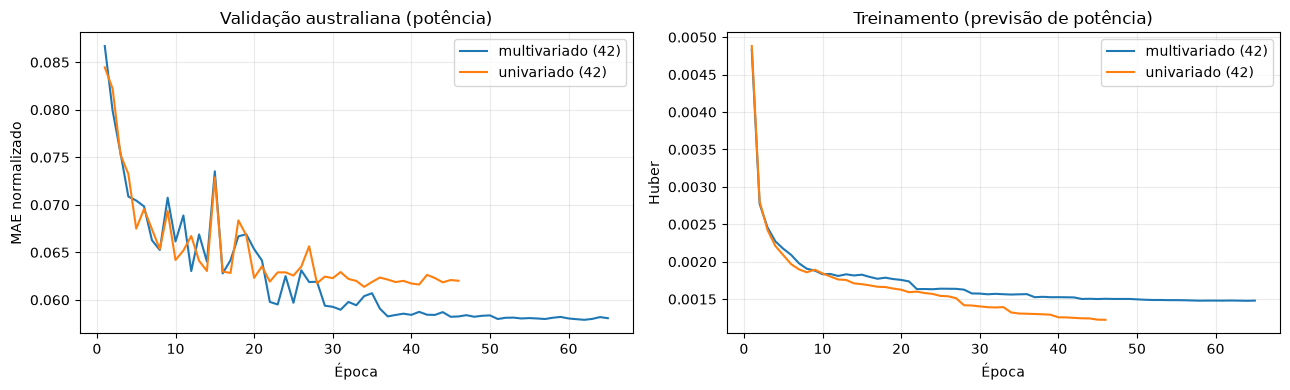

Pré-treinamento pronto. Checkpoints salvos em: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_07_pretreino_patchtst


In [5]:
historico=pd.DataFrame(historicos)
fig,ax=plt.subplots(1,2,figsize=(13,4))
for (seed,variante),g in historico.groupby(['seed','variante']):
    ax[0].plot(g.epoca,g.mae_validacao_normalizado,label=f'{variante} ({seed})')
    ax[1].plot(g.epoca,g.loss_previsao_treino,label=f'{variante} ({seed})')
ax[0].set(title='Validação australiana (potência)',xlabel='Época',ylabel='MAE normalizado')
ax[1].set(title='Treinamento (previsão de potência)',xlabel='Época',ylabel='Huber')
for a in ax:a.grid(alpha=.25);a.legend()
plt.tight_layout();plt.savefig(SAIDA_BASE/'curvas_pre_treinamento.png',dpi=150);plt.show()
manifesto={'etapa':'03_07','data_utc':datetime.now(timezone.utc).isoformat(),
           'config':CONFIG_MODELO,'seeds':SEEDS,'epochs_max':EPOCAS,
           'early_stopping':PACIENCIA,'lambda_ssl':LAMBDA_SSL,
           'mask_ratio':MASCARA_FRAC,'normalizacao_treino_au':ESCALA_AU,
           'arquivos_03_04':{'treino':raw_train['hash_sha256'],'validacao':raw_val['hash_sha256']},
           'descricao':'PatchTST compartilhado com reconstrucao mascarada historica; previsao sempre via potencia',
           'teste_nao_utilizado':not AVALIAR_TESTE_AUSTRALIANO}
(SAIDA_BASE/'manifesto.json').write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding='utf-8')
print('Pré-treinamento pronto. Checkpoints salvos em:',SAIDA_BASE)


## 6. Teste australiano final (opcional, bloqueado por padrão)

Somente habilite após fechar as escolhas metodológicas. Não use este resultado para otimizar hiperparâmetros.

In [6]:
if not AVALIAR_TESTE_AUSTRALIANO:
    print('Teste australiano preservado (AVALIAR_TESTE_AUSTRALIANO=False).')
else:
    raw_teste=ler_npz('australia','teste')
    TESTE_AU=normalizar(raw_teste,ESCALA_AU)
    linhas=[]
    for seed in SEEDS:
        for variante in ['univariado','multivariado']:
            arquivo=SAIDA_BASE/f'L240_H24_seed{seed}'/f'patchtst_australia_{variante}.pt'
            ck=torch.load(arquivo,map_location='cpu',weights_only=True)
            mm=PatchTSTCompartilhado(**ck['model_config']).to(DEVICE)
            mm.load_state_dict(ck['model_state_dict'],strict=True)
            pred=prever(mm,{'x':TESTE_AU['x'][:,:,-1:]},BATCH_SIZE)
            linhas.append({'variante':variante,'seed':seed,**resumo_metricas(TESTE_AU,pred,ESCALA_AU)})
    tabela=pd.DataFrame(linhas)
    display(tabela.round(4))
    tabela.to_csv(SAIDA_BASE/'metricas_teste_australia_final.csv',index=False)


Teste australiano preservado (AVALIAR_TESTE_AUSTRALIANO=False).
